In [21]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [22]:
import json
import sys
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import dask
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import regionmask
import rioxarray as rxr
import seaborn as sns
import xarray as xr
from dask.diagnostics import ProgressBar

sys.path.append("../..")

from src.utils.constants import (
    EXTENT_BC,
    EXTENT_BC_MRRO,
    REFERENCE_PERIOD,
    MID_CENTURY_PERIOD,
)
from src.utils.utils_xarray import sel_extent
from src.data_processing.load_data import ClimateModelData
from src.conversion_energy.hydropower import simple_hydropower_potential

sns.set_style("whitegrid", {"grid.color": ".93"})

In [23]:
paths = json.load(open("../../paths_so4.json"))

path_data_analysis = Path(paths["path_data_analysis"])
path_data_processed = Path(paths["path_data_processed"])
path_data_cordex = Path(paths["path_data_cordex"])
path_data_adjusted_cordex = Path(paths["path_data_adjusted_cordex"])
path_data_cerra = Path(paths["path_data_cerra"])
path_data_cerra_land = Path(paths["path_data_cerra_land"])
path_data_personal = Path(paths["path_data_personal"])
path_data_personal_cordex = path_data_personal / "cordex"
path_data_temporary = Path(paths["path_data_temporary"])

path_energy_ch = path_data_processed / "energy" / "ch"
path_energy_europe = path_data_processed / "energy" / "europe"

path_figs = Path(paths["path_figs"])

In [49]:
extent = {"lat_min": 30, "lat_max": 72.6, "lon_min": -12, "lon_max": 34}
extent_ch = {"lat_min": 45.8, "lat_max": 47.9, "lon_min": 5.9, "lon_max": 10.5}
extent_pop = {"lat_min": 29, "lat_max": 76, "lon_min": -11, "lon_max": 31}

In [25]:
climate_model_chain = "CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1"
climate_scenario = "rcp85"

In [26]:
path_data_routed = Path("/net/rain/landclim/pseubert/out_rcm/hist/") / f"{climate_model_chain}_{climate_scenario}"
path_data_routed_zarr = sorted(list(path_data_routed.glob("*/Qrouted_historical_*.zarr")))

In [27]:
ds_routed = ClimateModelData(
    path_data_routed_zarr,
    chunks="auto",
    # extent={"lat_min": 75, "lat_max": 30, "lon_min": -30, "lon_max": 41},
    # extent={"lat_min": 47.9, "lat_max": 45.8, "lon_min": 5.9, "lon_max": 10.5},
    extent={
        "lat_min": EXTENT_BC["lat_max"],
        "lat_max": EXTENT_BC["lat_min"],
        "lon_min": EXTENT_BC["lon_min"],
        "lon_max": EXTENT_BC["lon_max"],
    },
    check_calendar=False,
)

In [28]:
ds_routed.ds_data

<xarray.Dataset> Size: 102GB
Dimensions:  (time: 39785, lat: 450, lon: 710)
Coordinates:
  * lat      (lat) float64 4kB 74.95 74.85 74.75 74.65 ... 30.25 30.15 30.05
  * lon      (lon) float64 6kB -29.95 -29.85 -29.75 -29.65 ... 40.75 40.85 40.95
  * time     (time) object 318kB 1991-01-01 12:00:00 ... 2099-12-31 12:00:00
Data variables:
    Qrouted  (time, lat, lon) float64 102GB dask.array<chunksize=(3, 450, 710), meta=np.ndarray>
Attributes:
    Conventions:        XXX
    contact:            Routed CMIP6 runoff: pauline.seubert@env.ethz.ch; Rou...
    creation_date:      2025-08-18 10:13:14
    history:            2025-08-18 10:13:14, XXX
    mRM_details:        Helmholtz Center for Environmental Research - UFZ, De...
    project:            Global routing of CMIP6 models using mRM.
    setup_description:  Routing the runoff from rcm_preprocessed model CNRM-A...
    simulation_type:    Runoff data from rcm_preprocessed experiment historical.
    title:              mRMv1.0 Runoff data from rcm_preprocessed experiment ...

In [50]:
ds_tas = ClimateModelData(
    path_data_processed /
    "cordex_processed" /
    f"{climate_model_chain}_{climate_scenario}" /
    "bias_corrected" /
    "3hr" /
    "tas.zarr",
    extent=EXTENT_BC
).ds_data
ds_tas = sel_extent(ds_tas, extent=extent)

In [51]:
output_path_hydropower = (
    path_data_processed / "energy"
    / "europe"
    / "hydropower"
    / f"{climate_model_chain}_{climate_scenario}"
)
ds_hydropower = sel_extent(xr.open_zarr(output_path_hydropower / f"hydropower_{climate_model_chain}_{climate_scenario}.zarr", chunks="auto"), extent=extent)
ds_hydropower = ds_hydropower.sortby("lat", ascending=True)

In [52]:
# Check if ds_tas and ds_hydropower have the same latitude and longitude coordinates
same_lat = np.allclose(ds_tas.lat.values, ds_hydropower.lat.values)
same_lon = np.allclose(ds_tas.lon.values, ds_hydropower.lon.values)

print(f"Same latitude grid: {same_lat}")
print(f"Same longitude grid: {same_lon}")

Same latitude grid: True
Same longitude grid: True


In [42]:
ds_hydropower = ds_hydropower.convert_calendar('standard', align_on='year')

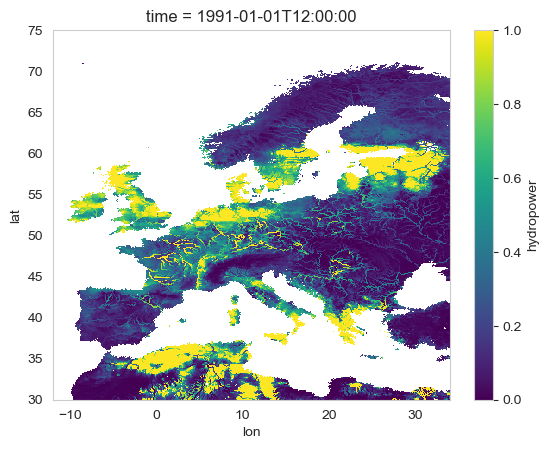

In [43]:
ds_hydropower.isel(time=0).hydropower.plot()

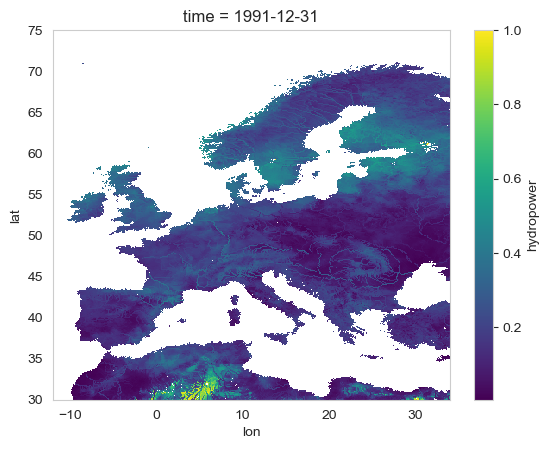

In [36]:
ds_hydropower.sel(time="1991").resample(time="YE").mean(dim="time").isel(time=0).hydropower.plot()

In [9]:
ds_routed.ds_data = ds_routed.ds_data.load()

In [ ]:
ds_hydropower = simple_hydropower_potential(
    ds_routed.ds_data,
    reference_period=REFERENCE_PERIOD,
    quantile_max=0.95,
    quantile_min=0.05,
).compute()

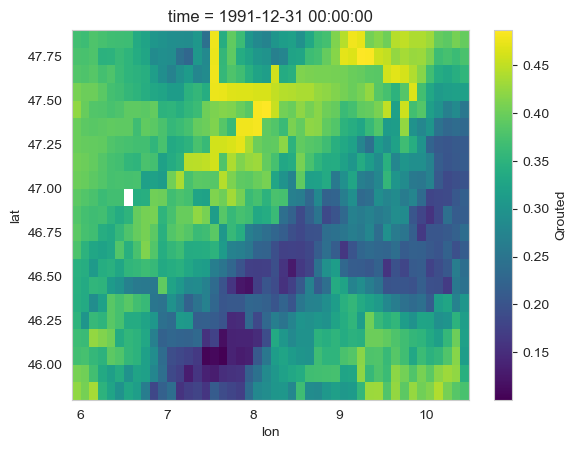

In [13]:
ds_hydropower.Qrouted.resample(time="YE").mean("time").isel(time=0).plot()

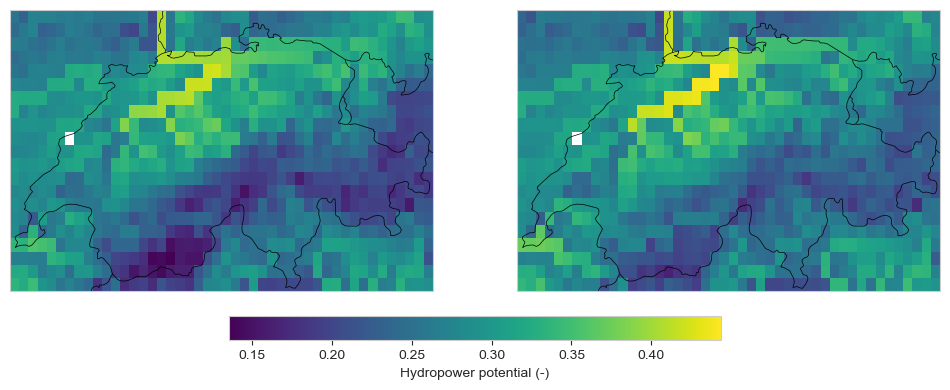

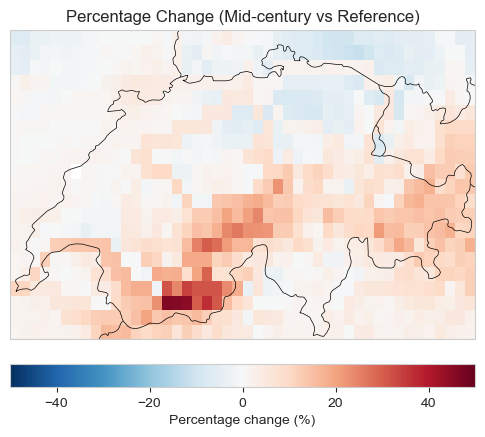

In [ ]:
fig, axs = plt.subplots(
    1, 2, figsize=(12, 8), subplot_kw={"projection": ccrs.Mercator()}
)

# Use the same colorbar for both subplots
ds_hydropower_mean_ref = ds_hydropower.Qrouted.sel(time=slice(*REFERENCE_PERIOD)).mean(
    "time"
)
ds_hydropower_mean_mid_century = ds_hydropower.Qrouted.sel(
    time=slice(*MID_CENTURY_PERIOD)
).mean("time")
vmin = min(
    [ds_hydropower_mean_ref.min().item(), ds_hydropower_mean_mid_century.min().item()]
)
vmax = max(
    [ds_hydropower_mean_ref.max().item(), ds_hydropower_mean_mid_century.max().item()]
)
ds_hydropower_mean_ref.plot(
    ax=axs[0],
    vmin=vmin,
    vmax=vmax,
    add_colorbar=False,
    transform=ccrs.PlateCarree(),
)
ds_hydropower_mean_mid_century.plot(
    ax=axs[1],
    vmin=vmin,
    vmax=vmax,
    add_colorbar=False,
    transform=ccrs.PlateCarree(),
)
for ax in axs:
    ax.coastlines()
    ax.add_feature(cfeature.BORDERS, edgecolor="black", linewidth=0.5)

cbar = fig.colorbar(
    axs[0].collections[0],
    ax=axs,
    orientation="horizontal",
    fraction=0.04,
    pad=0.04,
    label="Hydropower potential (-)",
)

# Calculate percentage change
percent_change = (
    100
    * (ds_hydropower_mean_mid_century - ds_hydropower_mean_ref)
    / ds_hydropower_mean_ref
)

# Add new subplot for percentage change
fig2, ax2 = plt.subplots(
    1, 1, figsize=(6, 8), subplot_kw={"projection": ccrs.Mercator()}
)
pcm = percent_change.plot(
    ax=ax2,
    cmap="RdBu_r",
    vmin=-50,
    vmax=50,
    add_colorbar=False,
    transform=ccrs.PlateCarree(),
)
ax2.coastlines()
ax2.add_feature(cfeature.BORDERS, edgecolor="black", linewidth=0.5)
cbar2 = fig2.colorbar(
    pcm,
    ax=ax2,
    orientation="horizontal",
    fraction=0.04,
    pad=0.04,
    label="Percentage change (%)",
)
ax2.set_title("Percentage Change (Mid-century vs Reference)")
plt.show()

In [40]:
path_data_routed = Path("/net/argon/landclim2/pseubert/out_rcm/hist/CNRM-85")
path_data_routed_zarr = list(path_data_routed.glob("*/Qrouted_historical_*_m3s.zarr"))

In [ ]:
ds_routed_rcp85 = ClimateModelData(
    path_data_routed_zarr,
    chunks="auto",
    # extent={"lat_min": 75, "lat_max": 30, "lon_min": -30, "lon_max": 41},
    extent={"lat_min": 47.9, "lat_max": 45.8, "lon_min": 5.9, "lon_max": 10.5},
    check_calendar=False,
)

In [42]:
ds_routed_rcp85.ds_data = ds_routed_rcp85.ds_data.load()

In [ ]:
ds_hydropower_rcp85 = simple_hydropower_potential(
    ds_routed_rcp85.ds_data,
    reference_period=REFERENCE_PERIOD,
    quantile_max=0.95,
    quantile_min=0.05,
).compute()

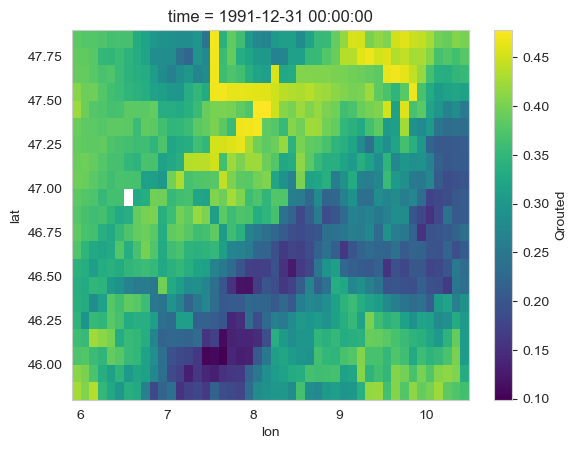

In [44]:
ds_hydropower_rcp85.Qrouted.resample(time="YE").mean("time").isel(time=0).plot()

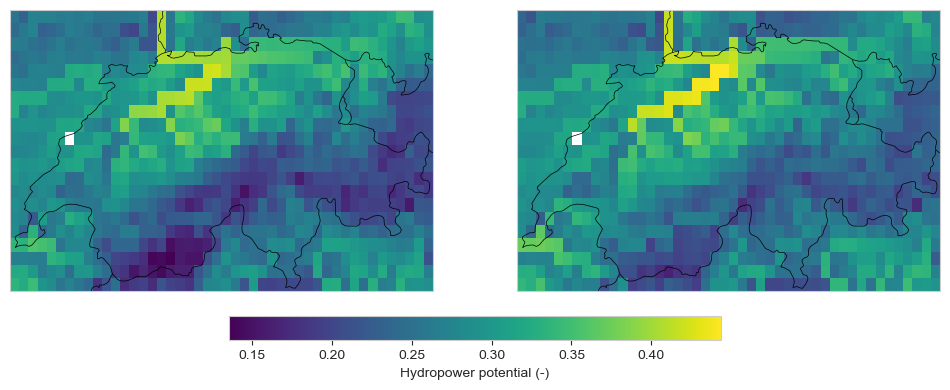

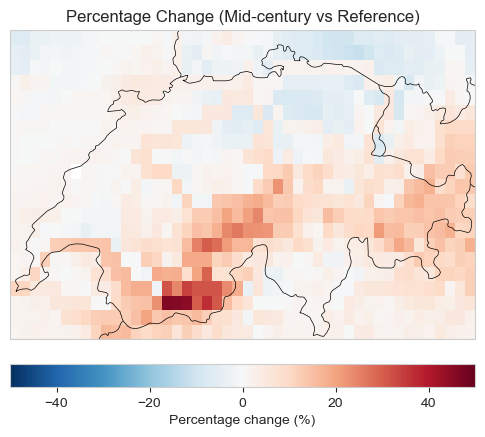

In [ ]:
fig, axs = plt.subplots(
    1, 2, figsize=(12, 8), subplot_kw={"projection": ccrs.Mercator()}
)

# Use the same colorbar for both subplots
ds_hydropower_rcp85_mean_ref = ds_hydropower_rcp85.Qrouted.sel(
    time=slice(*REFERENCE_PERIOD)
).mean("time")
ds_hydropower_rcp85_mean_mid_century = ds_hydropower_rcp85.Qrouted.sel(
    time=slice(*MID_CENTURY_PERIOD)
).mean("time")
vmin = min(
    [
        ds_hydropower_rcp85_mean_ref.min().item(),
        ds_hydropower_rcp85_mean_mid_century.min().item(),
    ]
)
vmax = max(
    [
        ds_hydropower_rcp85_mean_ref.max().item(),
        ds_hydropower_rcp85_mean_mid_century.max().item(),
    ]
)
ds_hydropower_rcp85_mean_ref.plot(
    ax=axs[0],
    vmin=vmin,
    vmax=vmax,
    add_colorbar=False,
    transform=ccrs.PlateCarree(),
)
ds_hydropower_rcp85_mean_mid_century.plot(
    ax=axs[1],
    vmin=vmin,
    vmax=vmax,
    add_colorbar=False,
    transform=ccrs.PlateCarree(),
)
for ax in axs:
    ax.coastlines()
    ax.add_feature(cfeature.BORDERS, edgecolor="black", linewidth=0.5)

cbar = fig.colorbar(
    axs[0].collections[0],
    ax=axs,
    orientation="horizontal",
    fraction=0.04,
    pad=0.04,
    label="Hydropower potential (-)",
)

# Calculate percentage change
percent_change_rcp85 = (
    100
    * (ds_hydropower_rcp85_mean_mid_century - ds_hydropower_rcp85_mean_ref)
    / ds_hydropower_rcp85_mean_ref
)

# Add new subplot for percentage change
fig2, ax2 = plt.subplots(
    1, 1, figsize=(6, 8), subplot_kw={"projection": ccrs.Mercator()}
)
pcm = percent_change_rcp85.plot(
    ax=ax2,
    cmap="RdBu_r",
    vmin=-50,
    vmax=50,
    add_colorbar=False,
    transform=ccrs.PlateCarree(),
)
ax2.coastlines()
ax2.add_feature(cfeature.BORDERS, edgecolor="black", linewidth=0.5)
cbar2 = fig2.colorbar(
    pcm,
    ax=ax2,
    orientation="horizontal",
    fraction=0.04,
    pad=0.04,
    label="Percentage change (%)",
)
ax2.set_title("Percentage Change (Mid-century vs Reference)")
plt.show()